# Chapter 8: Robust, adaptive and safety-critical control

A tracking controller assumes a perfect model and knows nothing of walls. This notebook reproduces the chapter's experiments:

1. a camera clipped on off-center, and the offset it leaves;
2. geometric L1 adaptive control on $\mathrm{SO}(3)$, with its state predictor, adaptation law and filter;
3. a barrier function for a point and a wall;
4. a cone on $S^2$, enforced by a quadratic program while the reference leaves it;
5. a tilt limit on $\mathrm{SO}(3)$.

Everything needs only NumPy and Matplotlib. The functions are the ones the book's verification script for this chapter checks.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np

E1, E2, E3 = np.eye(3)
I3 = np.eye(3)
GRAV = 9.81


def hat(v):
    x, y, z = v
    return np.array([[0.0, -z, y], [z, 0.0, -x], [-y, x, 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(w):
    """exp(hat(w)) by Rodrigues' formula."""
    th = np.linalg.norm(w)
    if th < 1e-12:
        return np.eye(3) + hat(w)
    K = hat(w / th)
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def unit(v):
    return np.asarray(v, float) / np.linalg.norm(v)

def Psi_R(R, Rd):
    return 0.5 * np.trace(I3 - Rd.T @ R)

def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)

def e_Omega(R, Om, Rd, Omd):
    return Om - R.T @ Rd @ Omd

def angle_between(R, Rd):
    return np.arccos(np.clip(1 - Psi_R(R, Rd), -1, 1))

## 1. What the tracker assumes

The plain controller: the PD law with feedforward of Chapter 6, written with the inertia $J_0$ that the controller believes,

$$\tau = \tau_{\mathrm{fb}} + \Omega\times J_0\Omega - J_0\big(\Omega\times R^\top R_d\,\Omega_d - R^\top R_d\,\dot\Omega_d\big), \qquad \tau_{\mathrm{fb}} = -k_R\,e_R - k_\Omega\,e_\Omega .$$

In [2]:
J0 = np.diag([6.968e-3, 6.211e-3, 10.34e-3])       # inertia the controller believes
M_ADD, R_ADD = 0.5, np.array([0.08, 0.0, -0.03])   # the camera: mass (kg) and place (m)
J_TRUE = J0 - M_ADD * hat(R_ADD) @ hat(R_ADD)
DELTA_CAM = M_ADD * GRAV * np.cross(E3, R_ADD)     # body torque in hover
K_R, K_OM = 2.0, 0.25
print("camera torque (N·m):", DELTA_CAM)


def feedforward(R, Om, Rd, Omd, Omd_dot, J):
    """Om x J Om - J (Om x R^T Rd Omd - R^T Rd Omd_dot): cancels everything but the feedback part."""
    return np.cross(Om, J @ Om) - J @ (hat(Om) @ R.T @ Rd @ Omd - R.T @ Rd @ Omd_dot)

def pd_torque(R, Om, Rd, Omd, Omd_dot, J=J0, k_R=K_R, k_Omega=K_OM):
    """The plain controller, equation (eq8-pd). Returns the torque and its feedback part."""
    tau_fb = -k_R * e_R(R, Rd) - k_Omega * e_Omega(R, Om, Rd, Omd)
    return tau_fb + feedforward(R, Om, Rd, Omd, Omd_dot, J), tau_fb

def lumped_uncertainty(R, Om, Rd, Omd, Omd_dot, tau_fb, Delta_e, J=J_TRUE, Jn=J0):
    """Delta of (eq8-lumped): J0 e_Omega_dot = tau_fb + Delta."""
    acc = hat(Om) @ R.T @ Rd @ Omd - R.T @ Rd @ Omd_dot
    Delta_m = -np.cross(Om, (J - Jn) @ Om) + (J - Jn) @ acc
    JJ = Jn @ np.linalg.inv(J)
    return (JJ - I3) @ tau_fb + JJ @ (Delta_m + Delta_e)

def ref_hover(t):
    return I3, np.zeros(3), np.zeros(3)

class ConingReference:
    """Rd(t) integrated from a smooth body rate. Call in increasing t with a fixed step."""

    def __init__(self, h, amp=0.9, rate=1.5, spin=0.3):
        self.h, self.amp, self.rate, self.spin = h, amp, rate, spin
        self.R, self.k = I3.copy(), 0

    def rates(self, t):
        a, w = self.amp, self.rate
        Omd = np.array([a * np.cos(w * t), a * np.sin(w * t), self.spin])
        Omd_dot = np.array([-a * w * np.sin(w * t), a * w * np.cos(w * t), 0.0])
        return Omd, Omd_dot

    def __call__(self, t):
        k = int(round(t / self.h))
        while self.k < k:                           # midpoint rule on the group
            tm = (self.k + 0.5) * self.h
            self.R = self.R @ expm_so3(self.h * self.rates(tm)[0])
            self.k += 1
        Omd, Omd_dot = self.rates(t)
        return self.R, Omd, Omd_dot

def gust(t):
    """A time-varying body torque, the shape used by Kotaru (2022, eq. 3.47), scaled."""
    s = 0.5 * (np.cos(t) + 0.5 * np.cos(3 * t + 0.23) + 0.5 * np.cos(5 * t - 0.4) + 0.5 * np.cos(7 * t + 2.09))
    return 0.25 * s * np.array([1.0, -0.6, 0.3])

def dist_camera(t):
    return DELTA_CAM

def dist_camera_gust(t):
    return DELTA_CAM + gust(t)

camera torque (N·m): [-0.      0.3924  0.    ]


## 2. What you do not know

With the true inertia $J$ and an unknown body torque $\Delta_e$, the error dynamics become $J_0\,\dot e_\Omega = \tau_{\mathrm{fb}} + \Delta$. The lumped uncertainty $\Delta$ enters where the input does. A constant torque leaves the offset $\sin\theta = \|\Delta_e\| / k_R$.

In [3]:
def proj(theta, y, bound, eps=0.1):
    """Smooth projection of Lavretsky and Gibson: acts for |theta| > bound / sqrt(1 + eps), keeps |theta| <= bound."""
    f = ((1 + eps) * theta @ theta - bound**2) / (eps * bound**2)
    grad = 2 * (1 + eps) * theta / (eps * bound**2)
    if f > 0 and y @ grad > 0:
        return y - grad * (grad @ y) / (grad @ grad) * f
    return y

class L1Attitude:
    """Geometric L1 adaptive attitude control (Kotaru 2022, ch. 3), book notation.

    State: predictor (Rp, Omp), estimate Dhat, filtered estimate Df.
    """

    def __init__(self, R0, Om0, h, k_Delta=4000.0, k_f=20.0, bound=3.0, c=0.01,
                 J=J0, k_R=K_R, k_Omega=K_OM, kRt=K_R, kOmt=K_OM):
        self.Rp, self.Omp = R0.copy(), Om0.copy()
        self.Dhat, self.Df = np.zeros(3), np.zeros(3)
        self.h, self.k_Delta, self.k_f, self.bound, self.c = h, k_Delta, k_f, bound, c
        self.J, self.Ji = J, np.linalg.inv(J)
        self.k_R, self.k_Omega, self.kRt, self.kOmt = k_R, k_Omega, kRt, kOmt

    def errors(self, R, Om):
        """Prediction errors: the predictor plays 'actual', the plant plays 'desired'."""
        return e_R(self.Rp, R), e_Omega(self.Rp, self.Omp, R, Om), Psi_R(self.Rp, R)

    def Xi(self, R):
        return self.J @ self.Rp.T @ R @ self.Ji @ R.T @ self.Rp

    def torques(self, R, Om, Rd, Omd, Omd_dot):
        """Return (tau, tau_fb, tau_fb_p) from the current controller state. Does not advance it."""
        J, Ji, Rp, Omp = self.J, self.Ji, self.Rp, self.Omp
        eRt, eOmt, _ = self.errors(R, Om)
        pd_p = -self.k_R * e_R(Rp, Rd) - self.k_Omega * e_Omega(Rp, Omp, Rd, Omd)
        tau_fb_p = pd_p + self.Xi(R) @ self.Dhat - self.Df
        eOm = e_Omega(R, Om, Rd, Omd)
        tau_fb = (J @ R.T @ Rp @ Ji @ (pd_p - self.Df + self.kRt * eRt + self.kOmt * eOmt)
              + J @ R.T @ Rp @ hat(eOmt) @ Rp.T @ R @ eOm)
        tau = tau_fb + feedforward(R, Om, Rd, Omd, Omd_dot, J)
        return tau, tau_fb, tau_fb_p

    def adapt_direction(self, R, Om):
        eRt, eOmt, _ = self.errors(R, Om)
        Xi = self.Xi(R)
        return -(Xi.T @ eOmt + self.c * Xi.T @ self.Ji.T @ eRt)

    def step(self, R, Om, Rd, Omd, Omd_dot):
        """One sampling period: torque from the current state, then advance the state.

        The estimate is advanced first and the predictor uses the new value
        (semi-implicit Euler), which keeps the fast estimate-predictor loop
        stable for sqrt(k_Delta / J) h < 2.
        """
        h = self.h
        tau, tau_fb, tau_fb_p = self.torques(R, Om, Rd, Omd, Omd_dot)
        self.last_tau_fb = tau_fb
        Xi = self.Xi(R)
        eRt, eOmt, _ = self.errors(R, Om)
        y = -(Xi.T @ eOmt + self.c * Xi.T @ self.Ji.T @ eRt)
        Dhat_new = self.Dhat + h * self.k_Delta * proj(self.Dhat, y, self.bound)
        size = np.linalg.norm(Dhat_new)
        if size > self.bound:                               # a finite step can overshoot the ball: pull it back
            Dhat_new = Dhat_new * (self.bound / size)
        tau_fb_p = tau_fb_p + Xi @ (Dhat_new - self.Dhat)
        self.Dhat = Dhat_new
        Omp_dot = self.Ji @ tau_fb_p - (hat(self.Omp) @ self.Rp.T @ Rd @ Omd - self.Rp.T @ Rd @ Omd_dot)
        Omp_new = self.Omp + h * Omp_dot
        self.Rp = self.Rp @ expm_so3(0.5 * h * (self.Omp + Omp_new))
        self.Omp = Omp_new
        self.Df = self.Df + (1 - np.exp(-self.k_f * h)) * (self.Dhat - self.Df)
        return tau

def body_step(R, Om, tau, h, J, Ji):
    """Rigid body, torque held over the step: RK4 on Omega, exact exponential on R."""
    def f(w):
        return Ji @ (tau - np.cross(w, J @ w))
    k1 = f(Om)
    k2 = f(Om + 0.5 * h * k1)
    k3 = f(Om + 0.5 * h * k2)
    k4 = f(Om + h * k3)
    Om_new = Om + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return R @ expm_so3(0.5 * h * (Om + Om_new)), Om_new

def run_attitude(controller, ref, dist, tf, h=1e-3, R0=I3, Om0=np.zeros(3), J=J_TRUE,
                 noise=0.0, lag=0.0, delay=0, seed=0, **kw):
    """Closed-loop attitude simulation.

    controller: "pd" or "l1".  noise: std of the gyroscope error (rad/s).
    lag: motor time constant (s).  delay: input delay in sampling periods.
    """
    rng = np.random.default_rng(seed)
    Ji = np.linalg.inv(J)
    n = int(round(tf / h))
    R, Om = R0.copy(), Om0.copy()
    l1 = L1Attitude(R, Om, h, **kw) if controller == "l1" else None
    tau_act, queue = np.zeros(3), [np.zeros(3)] * delay
    out = {k: np.zeros((n, 3)) for k in ("tau", "Dhat", "Df", "Delta", "Om")}
    out.update({k: np.zeros(n) for k in ("t", "Psi", "angle", "Psi_pred", "eOm_pred", "eOm", "Psi_p")})
    for k in range(n):
        t = k * h
        Rd, Omd, Omd_dot = ref(t)
        Om_meas = Om + noise * rng.normal(size=3)
        De = dist(t)
        if l1 is None:
            tau, tau_fb = pd_torque(R, Om_meas, Rd, Omd, Omd_dot)
        else:
            out["Psi_pred"][k] = Psi_R(l1.Rp, R)
            out["eOm_pred"][k] = np.linalg.norm(e_Omega(l1.Rp, l1.Omp, R, Om))
            out["Psi_p"][k] = Psi_R(l1.Rp, Rd)
            out["Dhat"][k], out["Df"][k] = l1.Dhat, l1.Df
            tau = l1.step(R, Om_meas, Rd, Omd, Omd_dot)
            tau_fb = l1.last_tau_fb
        out["Delta"][k] = lumped_uncertainty(R, Om, Rd, Omd, Omd_dot, tau_fb, De, J)
        out["t"][k], out["Psi"][k], out["angle"][k] = t, Psi_R(R, Rd), angle_between(R, Rd)
        out["eOm"][k] = np.linalg.norm(e_Omega(R, Om, Rd, Omd))
        out["tau"][k], out["Om"][k] = tau, Om
        if delay:
            queue.append(tau)
            tau = queue.pop(0)
        tau_act = tau if lag <= 0 else tau_act + (1 - np.exp(-h / lag)) * (tau - tau_act)
        R, Om = body_step(R, Om, tau_act + De, h, J, Ji)
        bad = not np.all(np.isfinite(Om)) or np.linalg.norm(Om) > 1e3
        if l1 is not None:
            bad = bad or not np.all(np.isfinite(l1.Omp)) or np.linalg.norm(l1.Omp) > 1e3
        if bad:
            for key in out:
                out[key] = out[key][:k + 1]
            out["diverged"] = True
            break
    out["R_final"] = R
    out.setdefault("diverged", False)
    return out

In [4]:
o_pd = run_attitude("pd", ref_hover, dist_camera, 4.0)
print(f"offset: {np.degrees(o_pd['angle'][-1]):.2f} deg,  "
      f"predicted: {np.degrees(np.arcsin(np.linalg.norm(DELTA_CAM) / K_R)):.2f} deg")

offset: 11.31 deg,  predicted: 11.31 deg


## 3. A co-pilot who learns

The class `L1Attitude` above holds the state predictor $(R_p, \Omega_p)$, the estimate $\hat\Delta$ and the filtered estimate $\Delta_f$. One call of `step` computes the torque from

$$\tau_{\mathrm{fb}} = J_0 R^\top R_p J_0^{-1}\big(-k_R e_R^p - k_\Omega e_\Omega^p - \Delta_f + \tilde k_R\tilde e_R + \tilde k_\Omega\tilde e_\Omega\big) + J_0 R^\top R_p\,\tilde e_\Omega^\wedge R_p^\top R\,e_\Omega,$$

then advances $\dot{\hat\Delta} = k_\Delta\,\operatorname{Proj}(\hat\Delta, y)$ with the adaptation gain $k_\Delta$, the predictor, and the filter $\dot\Delta_f = k_f(\hat\Delta - \Delta_f)$ with the cutoff $k_f$.

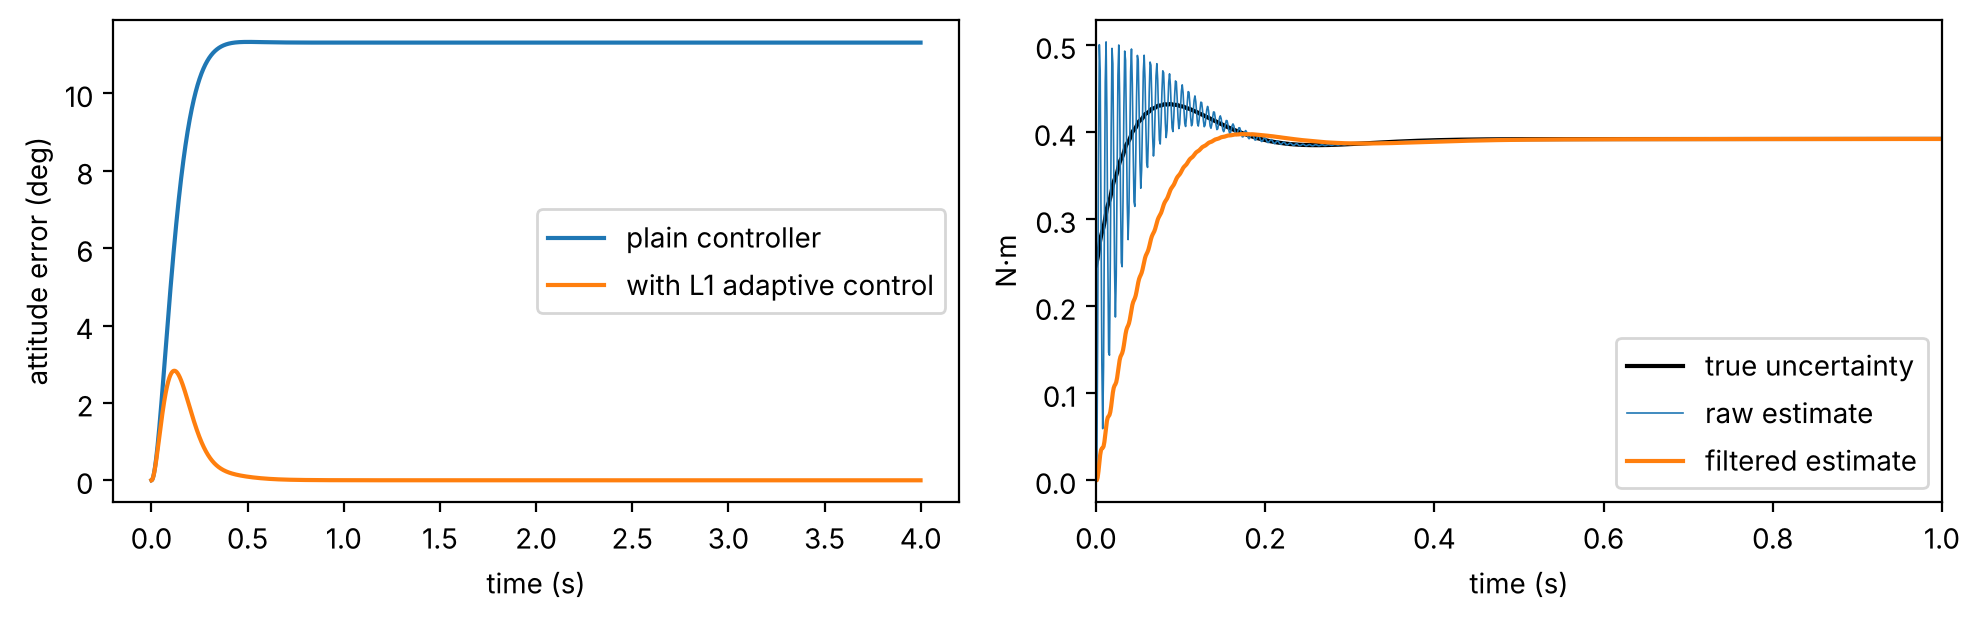

L1 peak error 2.83 deg, final 1.7e-06 deg


In [5]:
o_l1 = run_attitude("l1", ref_hover, dist_camera, 4.0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(o_pd["t"], np.degrees(o_pd["angle"]), label="plain controller")
ax[0].plot(o_l1["t"], np.degrees(o_l1["angle"]), label="with L1 adaptive control")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("attitude error (deg)"); ax[0].legend()
ax[1].plot(o_l1["t"], o_l1["Delta"][:, 1], "k", label="true uncertainty")
ax[1].plot(o_l1["t"], o_l1["Dhat"][:, 1], lw=0.6, label="raw estimate")
ax[1].plot(o_l1["t"], o_l1["Df"][:, 1], label="filtered estimate")
ax[1].set_xlim(0, 1); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("N·m"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"L1 peak error {np.degrees(o_l1['angle'].max()):.2f} deg, final {np.degrees(o_l1['angle'][-1]):.1e} deg")

## 4. Does it work?

A moving reference, the camera, and a gust torque. Then the same flight with gyroscope noise, for three filter cutoffs.

pd: RMS error 11.848 deg


l1: RMS error 0.570 deg


cutoff     1 rad/s: RMS error 3.059 deg, RMS torque rate 12 N·m/s


cutoff    30 rad/s: RMS error 0.397 deg, RMS torque rate 19 N·m/s


cutoff   300 rad/s: RMS error 0.058 deg, RMS torque rate 103 N·m/s


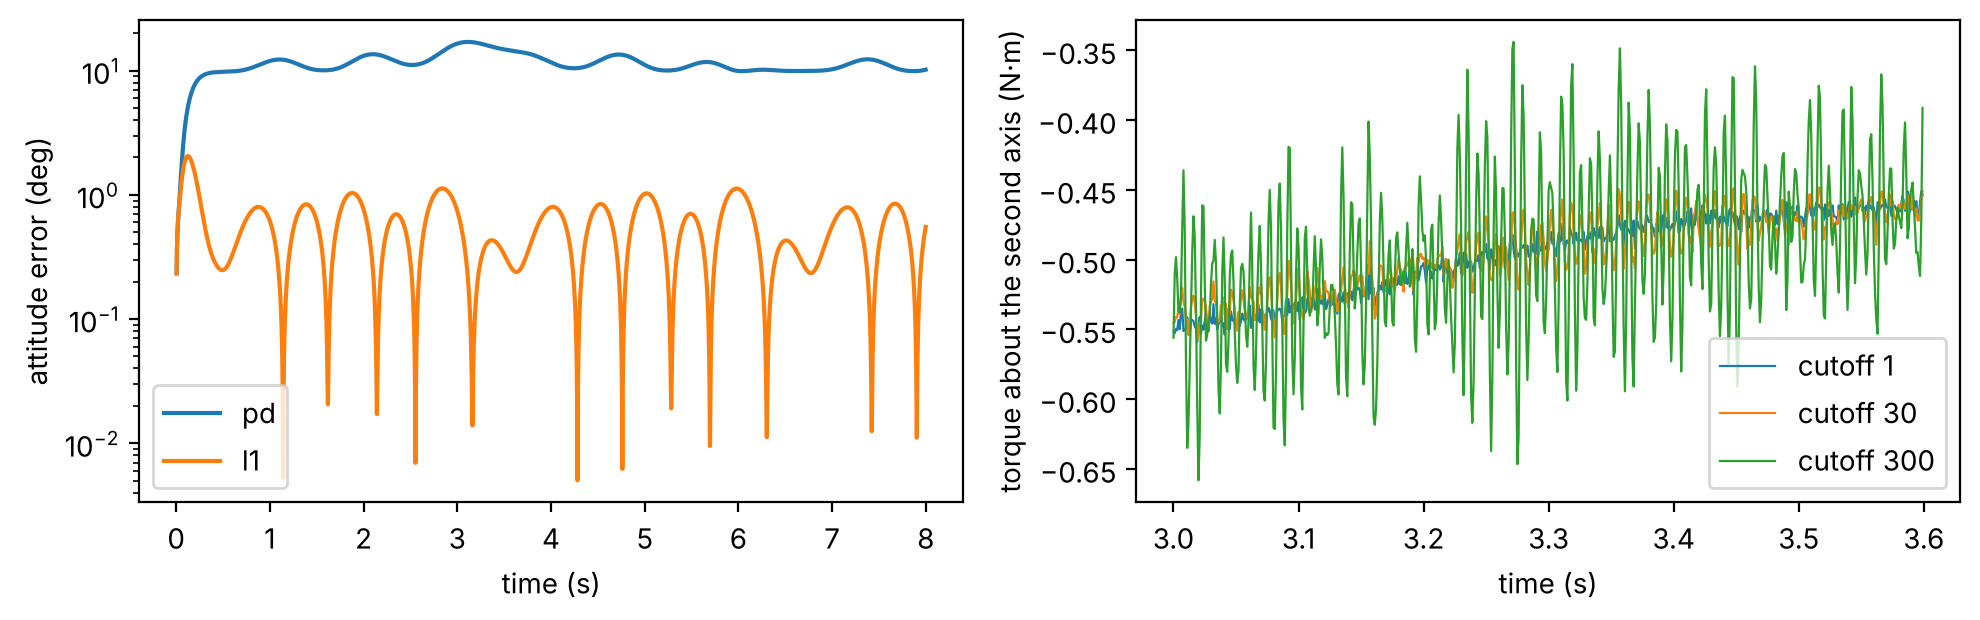

In [6]:
h = 1e-3
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for ctrl in ("pd", "l1"):
    o = run_attitude(ctrl, ConingReference(h), dist_camera_gust, 8.0)
    ax[0].semilogy(o["t"][5:], np.degrees(o["angle"][5:]), label=ctrl)
    rms = np.sqrt(np.mean(np.degrees(o["angle"][3000:])**2))
    print(f"{ctrl}: RMS error {rms:.3f} deg")
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("attitude error (deg)"); ax[0].legend()
for k_f in (1.0, 30.0, 300.0):
    o = run_attitude("l1", ConingReference(h), dist_camera_gust, 6.0, noise=0.02, k_f=k_f)
    rate = np.linalg.norm(np.diff(o["tau"], axis=0), axis=1) / h
    rms = np.sqrt(np.mean(np.degrees(o["angle"][3000:])**2))
    print(f"cutoff {k_f:5.0f} rad/s: RMS error {rms:.3f} deg, RMS torque rate {np.sqrt(np.mean(rate[3000:]**2)):.0f} N·m/s")
    ax[1].plot(o["t"][3000:3600], o["tau"][3000:3600, 1], lw=0.8, label=f"cutoff {k_f:g}")
ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("torque about the second axis (N·m)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Never, as opposed to eventually

A point with velocity input must not cross a wall. The barrier function is $H = d - n\cdot x$. The filter returns the velocity nearest to the tracker's $u_d$ that satisfies $\dot H \ge -\alpha H$:

$$u = u_d - \max(0,\ n\cdot u_d - \alpha H)\,n.$$

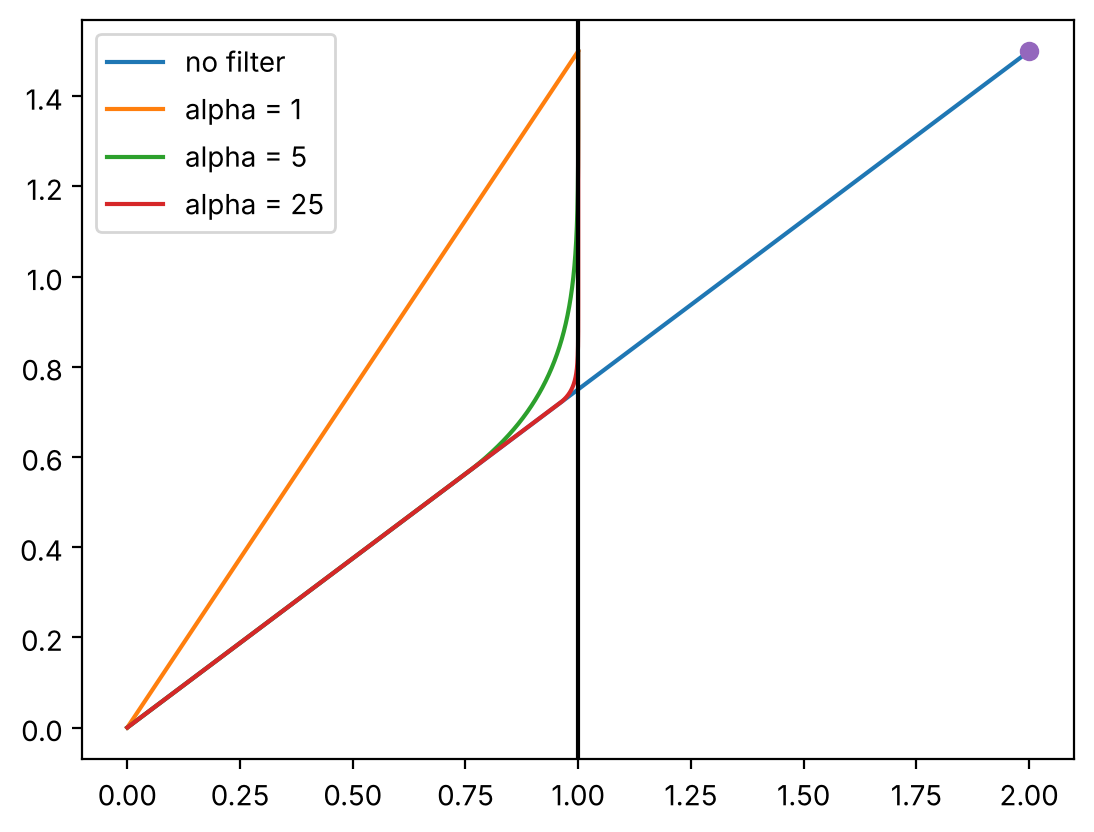

In [7]:
WALL_N, WALL_D = E1[:2], 1.0


def wall_H(x):
    return WALL_D - WALL_N @ x

def wall_filter(x, ud, alpha):
    """argmin |u - ud|^2  s.t.  H_dot = -n.u >= -alpha H   (closed form)."""
    return ud - max(0.0, WALL_N @ ud - alpha * wall_H(x)) * WALL_N

def run_wall(alpha, x0=(0.0, 0.0), xd=(2.0, 1.5), k=1.0, tf=8.0, h=1e-3):
    n = int(round(tf / h))
    xs = np.zeros((n + 1, 2))
    xs[0] = x0
    xd = np.asarray(xd, float)
    for i in range(n):
        ud = -k * (xs[i] - xd)
        u = ud if alpha is None else wall_filter(xs[i], ud, alpha)
        xs[i + 1] = xs[i] + h * u
    return np.arange(n + 1) * h, xs


for alpha in (None, 1.0, 5.0, 25.0):
    t, xs = run_wall(alpha)
    plt.plot(xs[:, 0], xs[:, 1], label="no filter" if alpha is None else f"alpha = {alpha:g}")
plt.axvline(1.0, color="k"); plt.plot([2], [1.5], "o"); plt.axis("equal"); plt.legend(); plt.show()

## 6. Barriers on the sphere

A pendulum direction $q \in S^2$ must stay within $\theta_{\max}$ of the axis $q_c$: $H = q\cdot q_c - \cos\theta_{\max}$. Its derivatives are

$$\dot H = \omega\cdot(q\times q_c), \qquad \ddot H = -\|\omega\|^2 (q\cdot q_c) + (I - q q^\top) q_c\cdot\frac{F - m g\,e_3}{m\,l}.$$

With $H_1 = \dot H + \alpha_1 H$, the program (the CBF-CLF-QP) minimizes $\tfrac12\|F_{\mathrm{fb}}\|^2 + \tfrac12 k_w w^2$ subject to $\dot V + k_V V \le w$ and $\dot H_1 + \alpha_2 H_1 \ge 0$, with the slack variable $w$ and
$V = m l^2\big(\tfrac12\|e_\omega\|^2 + k_q\Psi_q + c\,e_q\cdot e_\omega\big)$. The code stores the gains as $m l^2 k_q$ and $m l^2 k_\omega$.

In [8]:
M_P, L_P = 0.5, 0.8
ML2_K_Q, ML2_K_OMEGA, C_V = 12.0, 2.5, 1.0         # m l^2 k_q (N·m), m l^2 k_omega (N·m·s), and c of V on S^2
CONE_AXIS, CONE_ANGLE = -E3, np.radians(30.0)


def solve_qp(Q, c, A, b, tol=1e-9):
    """min 0.5 z'Qz + c'z  subject to  A z <= b, for a handful of constraints.

    Tries every active set, smallest first, and returns the first KKT point.
    Returns None when the constraints cannot all be met. Q must be positive definite.

    An active set whose rows are dependent (a repeated row, a multiple of another, a
    row that is numerically zero, more rows than unknowns) makes the KKT matrix
    singular, and its solve can return a huge point. Such sets are skipped: when the
    optimum has dependent active constraints, an independent subset of them carries
    nonnegative multipliers and gives the same point, and it is tried earlier. The
    test of a candidate uses tolerances scaled by the data, never by the candidate.
    """
    from itertools import combinations
    n, m = len(c), len(b)
    sA = max(1.0, np.abs(A).max()) if m else 1.0                  # scale of the constraints
    sQ = max(1.0, np.abs(Q).max(), np.abs(c).max() if n else 0.0)
    bound = 1e9 * (1.0 + np.abs(np.linalg.solve(Q, -c)).max() + (np.abs(b).max() if m else 0.0) / sA)
    for size in range(min(m, n) + 1):
        for act in combinations(range(m), size):
            act = list(act)
            if act:
                Aa = A[act]
                if np.linalg.svd(Aa, compute_uv=False)[-1] <= 1e-9 * sA:
                    continue                                       # dependent rows: singular KKT matrix
                K = np.block([[Q, Aa.T], [Aa, np.zeros((size, size))]])
                try:
                    sol = np.linalg.solve(K, np.concatenate([-c, b[act]]))
                except np.linalg.LinAlgError:
                    continue
                z, lam = sol[:n], sol[n:]
            else:
                Aa = A[:0]
                z, lam = np.linalg.solve(Q, -c), np.zeros(0)
            if not (np.all(np.isfinite(z)) and np.all(np.isfinite(lam)) and np.abs(z).max(initial=0.0) <= bound):
                continue
            stat = np.abs(Q @ z + c + Aa.T @ lam).max(initial=0.0)
            prim = np.abs(Aa @ z - b[act]).max(initial=0.0)
            if (np.all(A @ z <= b + tol * (1 + np.abs(b))) and np.all(lam >= -tol)
                    and stat <= 1e-6 * sQ * (1.0 + bound / 1e9) and prim <= 1e-6 * sA * (1.0 + bound / 1e9)):
                return z
    return None

def s2_accel(q, om, F):
    """m l^2 om_dot = -m g l q x e3 + l q x F   (eq7-pendulum)."""
    return np.cross(q, F - M_P * GRAV * E3) / (M_P * L_P)

def Psi_q(q, qd):
    return 1 - q @ qd

def e_q(q, qd):
    return np.cross(qd, q)

def e_omega(q, om, omd):
    return om - (omd - (q @ omd) * q)

class CircleReference:
    """qd moves at constant rate on a small circle about the axis c."""

    def __init__(self, c, q0, rate):
        self.c, self.q0, self.rate = unit(c), unit(q0), rate

    def __call__(self, t):
        c, w = self.c, self.rate
        qd = expm_so3(w * t * c) @ self.q0
        qd_dot = w * np.cross(c, qd)
        omd = np.cross(qd, qd_dot)                 # tangent: omd . qd = 0
        qd_ddot = w * np.cross(c, qd_dot)
        omd_dot = np.cross(qd, qd_ddot)
        return qd, omd, omd_dot

def s2_reference_accel(q, om, omd, omd_dot):
    """a_d = d/dt[(I - q q^T) omd], so that e_omega_dot = om_dot - a_d."""
    q_dot = np.cross(om, q)
    return omd_dot - (q @ omd_dot) * q - q_dot * (q @ omd) - q * (q_dot @ omd)

def s2_feedforward(q, om, omd, omd_dot):
    """Force that makes the tangent part of e_omega_dot vanish."""
    a = s2_reference_accel(q, om, omd, omd_dot)
    w = a - (a @ q) * q + GRAV / L_P * np.cross(q, E3)
    return -M_P * L_P * np.cross(q, w)

def s2_pd_force(q, om, qd, omd, omd_dot, ml2_k_q=ML2_K_Q, ml2_k_omega=ML2_K_OMEGA):
    """The direction law with feedforward on S^2, as a force on the bob."""
    fb = -(ml2_k_q * e_q(q, qd) + ml2_k_omega * e_omega(q, om, omd)) / (M_P * L_P**2)
    return s2_feedforward(q, om, omd, omd_dot) - M_P * L_P * np.cross(q, fb)

def s2_V(q, om, qd, omd, ml2_k_q=ML2_K_Q, c=C_V):
    eq, ew = e_q(q, qd), e_omega(q, om, omd)
    return 0.5 * M_P * L_P**2 * ew @ ew + ml2_k_q * Psi_q(q, qd) + c * M_P * L_P**2 * eq @ ew

def s2_V_dot_terms(q, om, qd, omd, omd_dot, ml2_k_q=ML2_K_Q, c=C_V):
    """V_dot = aV + bV . F."""
    ml2 = M_P * L_P**2
    eq, ew = e_q(q, qd), e_omega(q, om, omd)
    a_d = s2_reference_accel(q, om, omd, omd_dot)
    eq_dot = (q @ qd) * ew + (q @ omd) * np.cross(q, eq) - (qd @ om) * q
    aV = ml2 * (ew + c * eq) @ (-GRAV / L_P * np.cross(q, E3) - a_d) + ml2_k_q * eq @ ew + c * ml2 * eq_dot @ ew
    bV = L_P * np.cross(ew + c * eq, q)
    return aV, bV

def cone_static(t):
    return CONE_AXIS, np.zeros(3), np.zeros(3)

def cone_H(q, om, qc, qc_dot, qc_ddot, angle=CONE_ANGLE):
    """H, H_dot, and H_ddot = aH + bH . F for the cone H = q . qc - cos(angle)."""
    q_dot = np.cross(om, q)
    H = q @ qc - np.cos(angle)
    H_dot = q_dot @ qc + q @ qc_dot
    tang = qc - (q @ qc) * q                                # (I - q q^T) qc
    aH = -(om @ om) * (q @ qc) - GRAV / L_P * (E3 @ tang) + 2 * q_dot @ qc_dot + q @ qc_ddot
    bH = tang / (M_P * L_P)
    return H, H_dot, aH, bH

def s2_safe_force(t, q, om, ref, cone=cone_static, alpha1=6.0, alpha2=6.0, kV=4.0, kslack=50.0,
                  angle=CONE_ANGLE, Fmax=None):
    """CBF-CLF-QP on S^2 (eq8-qp). Returns F, slack, and whether the QP was feasible."""
    qd, omd, omd_dot = ref(t)
    Fff = s2_feedforward(q, om, omd, omd_dot)
    aV, bV = s2_V_dot_terms(q, om, qd, omd, omd_dot)
    V = s2_V(q, om, qd, omd)
    H, H_dot, aH, bH = cone_H(q, om, *cone(t), angle=angle)
    H1 = H_dot + alpha1 * H
    Q = np.diag([1.0, 1.0, 1.0, kslack])
    A = [np.concatenate([bV, [-1.0]]), np.concatenate([-bH, [0.0]])]
    b = [-kV * V - aV - bV @ Fff, aH + bH @ Fff + alpha1 * H_dot + alpha2 * H1]
    if Fmax is not None:                                    # box on the total force
        for i in range(3):
            row = np.zeros(4)
            row[i] = 1.0
            A += [row, -row]
            b += [Fmax - Fff[i], Fmax + Fff[i]]
    z = solve_qp(Q, np.zeros(4), np.array(A), np.array(b))
    if z is None:
        return Fff, np.nan, False
    return Fff + z[:3], z[3], True

def s2_step(q, om, F, h):
    """RK4 with the force held, then back onto the sphere."""
    def f(q_, om_):
        return np.cross(om_, q_), s2_accel(q_, om_, F)
    k1 = f(q, om)
    k2 = f(q + 0.5 * h * k1[0], om + 0.5 * h * k1[1])
    k3 = f(q + 0.5 * h * k2[0], om + 0.5 * h * k2[1])
    k4 = f(q + h * k3[0], om + h * k3[1])
    q = unit(q + h / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0]))
    om = om + h / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return q, om - (om @ q) * q

def run_cone(ref, tf, h=2e-3, controller="qp", cone=cone_static, q0=None, om0=None, wind=None, **kw):
    """Pendulum on S^2 under the CBF-CLF-QP ("qp") or the tracker alone ("pd").

    wind: a constant force on the bob that the controller does not know about.
    """
    n = int(round(tf / h))
    wind = np.zeros(3) if wind is None else np.asarray(wind, float)
    qd0, omd0, _ = ref(0.0)
    q = qd0.copy() if q0 is None else unit(q0)
    om = (omd0 - (omd0 @ q) * q) if om0 is None else np.asarray(om0, float)
    out = {k: np.zeros((n, 3)) for k in ("q", "qd", "F", "qc")}
    out.update({k: np.zeros(n) for k in ("t", "H", "H1", "V", "slack", "Psi")})
    out["feasible"] = np.ones(n, bool)
    a1 = kw.get("alpha1", 6.0)
    for k in range(n):
        t = k * h
        qd, omd, omd_dot = ref(t)
        if controller == "qp":
            F, slack, ok = s2_safe_force(t, q, om, ref, cone=cone, **kw)
        else:
            F, slack, ok = s2_pd_force(q, om, qd, omd, omd_dot), 0.0, True
        ang = kw.get("angle", CONE_ANGLE)
        H, H_dot, _, _ = cone_H(q, om, *cone(t), angle=ang)
        out["t"][k], out["q"][k], out["qd"][k], out["F"][k] = t, q, qd, F
        out["qc"][k] = cone(t)[0]
        out["H"][k], out["H1"][k] = H, H_dot + a1 * H
        out["V"][k], out["slack"][k], out["Psi"][k] = s2_V(q, om, qd, omd), slack, Psi_q(q, qd)
        out["feasible"][k] = ok
        q, om = s2_step(q, om, F + wind, h)
    return out

def cone_reference():
    """The reference of the cone example: a circle of radius 26 deg about an axis 22 deg off -e3."""
    tilt, rad = np.radians(22.0), np.radians(26.0)
    c = np.array([np.sin(tilt), 0.0, -np.cos(tilt)])
    q0 = np.array([np.sin(tilt - rad), 0.0, -np.cos(tilt - rad)])
    return CircleReference(c, q0, 0.9)

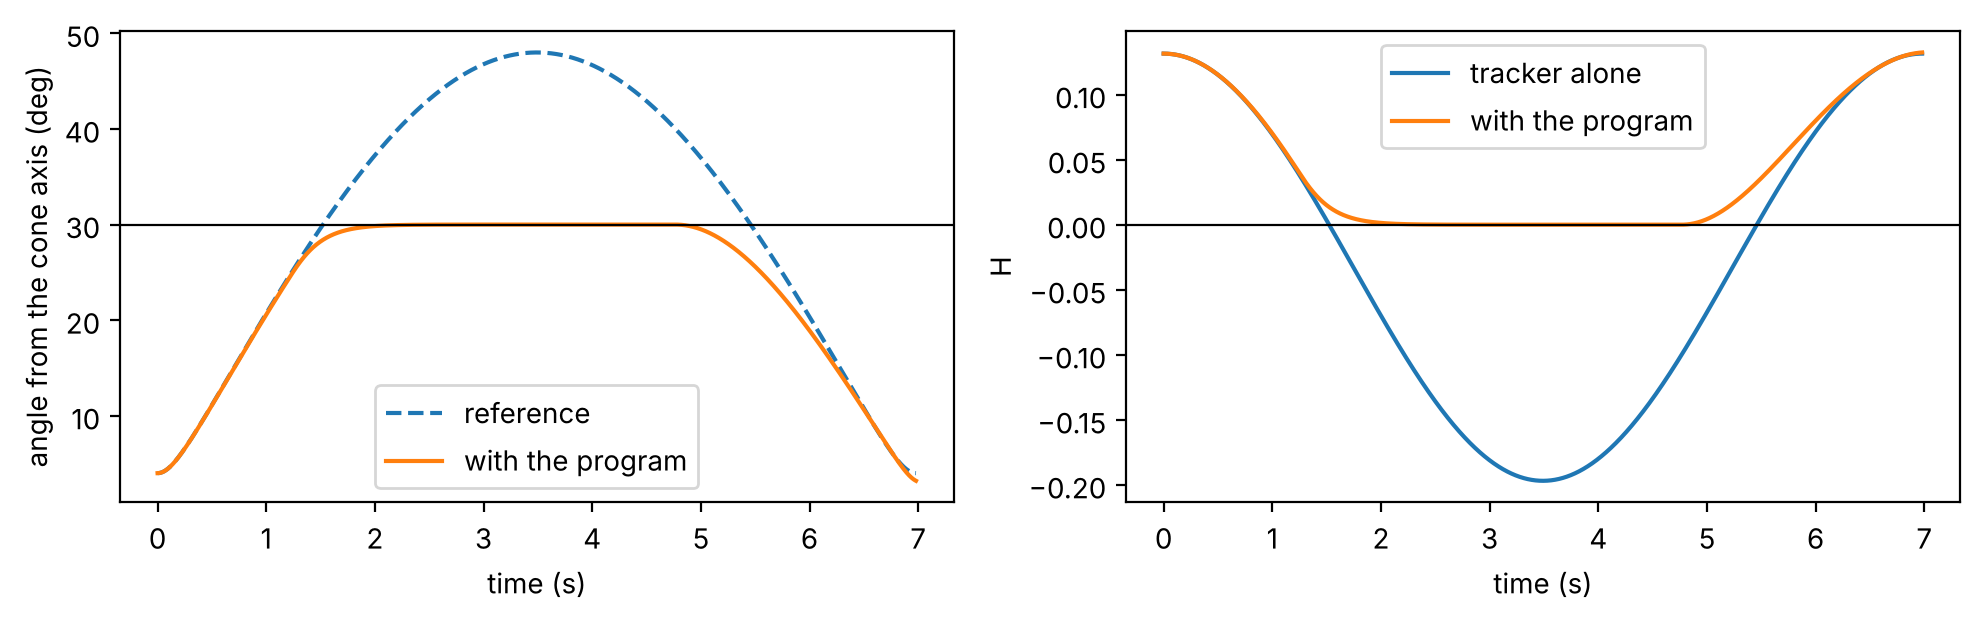

min H: tracker alone -0.197, with the program 3.3e-07


In [9]:
ref = cone_reference()
lap = 2 * np.pi / 0.9
o_free = run_cone(ref, lap, controller="pd")
o_safe = run_cone(ref, lap)
ang = lambda q: np.degrees(np.arccos(np.clip(-q[:, 2], -1, 1)))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(o_safe["t"], ang(o_safe["qd"]), "--", label="reference")
ax[0].plot(o_safe["t"], ang(o_safe["q"]), label="with the program")
ax[0].axhline(30, color="k", lw=0.8); ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("angle from the cone axis (deg)"); ax[0].legend()
ax[1].plot(o_free["t"], o_free["H"], label="tracker alone")
ax[1].plot(o_safe["t"], o_safe["H"], label="with the program")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("H"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"min H: tracker alone {o_free['H'].min():.3f}, with the program {o_safe['H'].min():.1e}")

**The same on $\mathrm{SO}(3)$.** A tilt limit is $H = e_3\cdot R\,e_3 - \cos\theta_{\max}$, with $\dot H = \Omega\cdot(e_3\times R^\top e_3)$.

In [10]:
def tilt_H(R, Om, angle):
    """H = e3 . R e3 - cos(angle), H_dot, and the parts of H_ddot = aH + bH . Om_dot."""
    b3 = R.T @ E3
    H = b3[2] - np.cos(angle)
    H_dot = Om @ np.cross(E3, b3)
    aH = -(Om @ Om) * b3[2] + (Om @ b3) * Om[2]
    bH = np.cross(E3, b3)
    return H, H_dot, aH, bH

def tilt_filter(R, Om, tau_d, angle, J, alpha1=8.0, alpha2=8.0):
    """argmin |tau - tau_d|^2  s.t.  H_ddot + (alpha1 + alpha2) H_dot + alpha1 alpha2 H >= 0."""
    Ji = np.linalg.inv(J)
    H, H_dot, aH, bH = tilt_H(R, Om, angle)
    g = Ji @ bH                                             # H_ddot = aH - bH.Ji(Om x J Om) + g . tau
    rhs = -(aH - bH @ Ji @ np.cross(Om, J @ Om)) - (alpha1 + alpha2) * H_dot - alpha1 * alpha2 * H
    short = rhs - g @ tau_d
    if short <= 0 or g @ g < 1e-14:
        return tau_d
    return tau_d + short * g / (g @ g)

def run_tilt(Rd, angle, tf=4.0, h=1e-3, J=J0, filtered=True):
    Ji = np.linalg.inv(J)
    n = int(round(tf / h))
    R, Om = I3.copy(), np.zeros(3)
    out = {"t": np.zeros(n), "H": np.zeros(n), "tilt": np.zeros(n), "Psi": np.zeros(n), "b3": np.zeros((n, 3))}
    for k in range(n):
        tau_d, _ = pd_torque(R, Om, Rd, np.zeros(3), np.zeros(3), J)
        tau = tilt_filter(R, Om, tau_d, angle, J) if filtered else tau_d
        out["t"][k], out["H"][k] = k * h, tilt_H(R, Om, angle)[0]
        out["tilt"][k], out["Psi"][k], out["b3"][k] = np.arccos(np.clip(R[2, 2], -1, 1)), Psi_R(R, Rd), R @ E3
        R, Om = body_step(R, Om, tau, h, J, Ji)
    out["R_final"] = R
    return out


o_t = run_tilt(expm_so3(np.radians(60) * E2), np.radians(35))
print(f"target 60 deg, limit 35 deg: the body stops at {np.degrees(o_t['tilt'][-1]):.3f} deg")

target 60 deg, limit 35 deg: the body stops at 35.000 deg


## Starting points for the exercises

- **Offset.** Change `M_ADD` and `R_ADD` and compare the rest attitude with $\sin\theta = \|\Delta_e\|/k_R$. Start `run_attitude("pd", ...)` from `R0 = expm_so3(np.radians(170) * E2)` and see which equilibrium it finds.
- **Integral term.** Add a state to `pd_torque` and compare with L1 under `dist_camera_gust`. `run_attitude(..., delay=d)` delays the torque by `d` sampling periods.
- **Projection.** `proj(theta, y, bound)` is the operator of the chapter. Sample random pairs and test the inequality.
- **Wind.** `run_cone(ref, lap, wind=np.array([1.0, 0, 0]))` adds a force the program does not know. Try `alpha1=18, alpha2=18`, and a tightened cone with `angle=np.radians(25)`.
- **The sigmoid.** The cell below tests Wu's third condition for a sigmoid.

In [11]:
def third_condition(k1, k2, p0, beta, r_o=0.6):
    """Smallest value of 2p - sigma'(p) on (-sqrt(beta) r_o, 0) for sigma = k1 tanh(k2 (p0 - p))."""
    p = np.linspace(-np.sqrt(beta) * r_o, 0, 2001)[1:-1]
    d_sigma = -k1 * k2 / np.cosh(k2 * (p0 - p))**2
    return (2 * p - d_sigma).min()


print("chapter's sigmoid:", third_condition(0.25, 2.0, 0.0, 1.8))
o = run_cone(ref, 1.5 * lap, wind=np.array([1.0, 0.0, 0.0]))
print(f"unknown 1 N wind: min H = {o['H'].min():.4f}")

chapter's sigmoid: -1.5351620453938566


unknown 1 N wind: min H = -0.0316
